# Pose classifier evaluation

Confusion matrix and per-class stats for the trained landmark classifier
(`exports/pose_classifier.pt`). Reproduces the training split with the same
seed, so the numbers here match the held-out validation set the checkpoint was
selected on.

Run the training pipeline first if the artifacts are missing:

```bash
python scripts/extract_landmarks.py
python scripts/train_landmarks.py
```

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from model.landmark_mlp import build_mlp

FEATURES = ROOT / "exports" / "landmark_features.json"
CKPT = ROOT / "exports" / "pose_classifier.pt"

## Load features and reproduce the training split

Same `test_size`, `random_state`, and stratify as `train_landmarks.py`, so the
validation rows here are exactly the ones held out during training. The val set
is not mirror-augmented, matching how the checkpoint was scored.

In [2]:
data = json.loads(FEATURES.read_text())
labels = data["labels"]
idx = {name: i for i, name in enumerate(labels)}
X = np.array([s["feature"] for s in data["samples"]], dtype=np.float32)
y = np.array([idx[s["label"]] for s in data["samples"]])

X_tr, X_val, y_tr, y_val = train_test_split(
    X, y, test_size=0.2, random_state=0, stratify=y
)
print(f"{len(labels)} classes, {len(X)} samples ({len(X_tr)} train, {len(X_val)} val)")

19 classes, 322 samples (257 train, 65 val)


## Load the trained model and predict on the validation set

In [3]:
ckpt = torch.load(CKPT, map_location="cpu", weights_only=True)
assert ckpt["labels"] == labels, "checkpoint labels differ from the feature cache"

model = build_mlp(len(labels))
model.load_state_dict(ckpt["state_dict"])
model.eval()

with torch.no_grad():
    logits = model(torch.from_numpy(X_val))
    probs = logits.softmax(1).numpy()
    y_pred = logits.argmax(1).numpy()

acc = (y_pred == y_val).mean()
print(f"validation accuracy: {acc:.3f} ({(y_pred == y_val).sum()}/{len(y_val)})")

validation accuracy: 0.923 (60/65)


## Confusion matrix

Rows are the true pose, columns the predicted. A clean diagonal means the
classifier separates the poses. Off-diagonal cells show which poses get confused,
usually ones with similar body geometry.

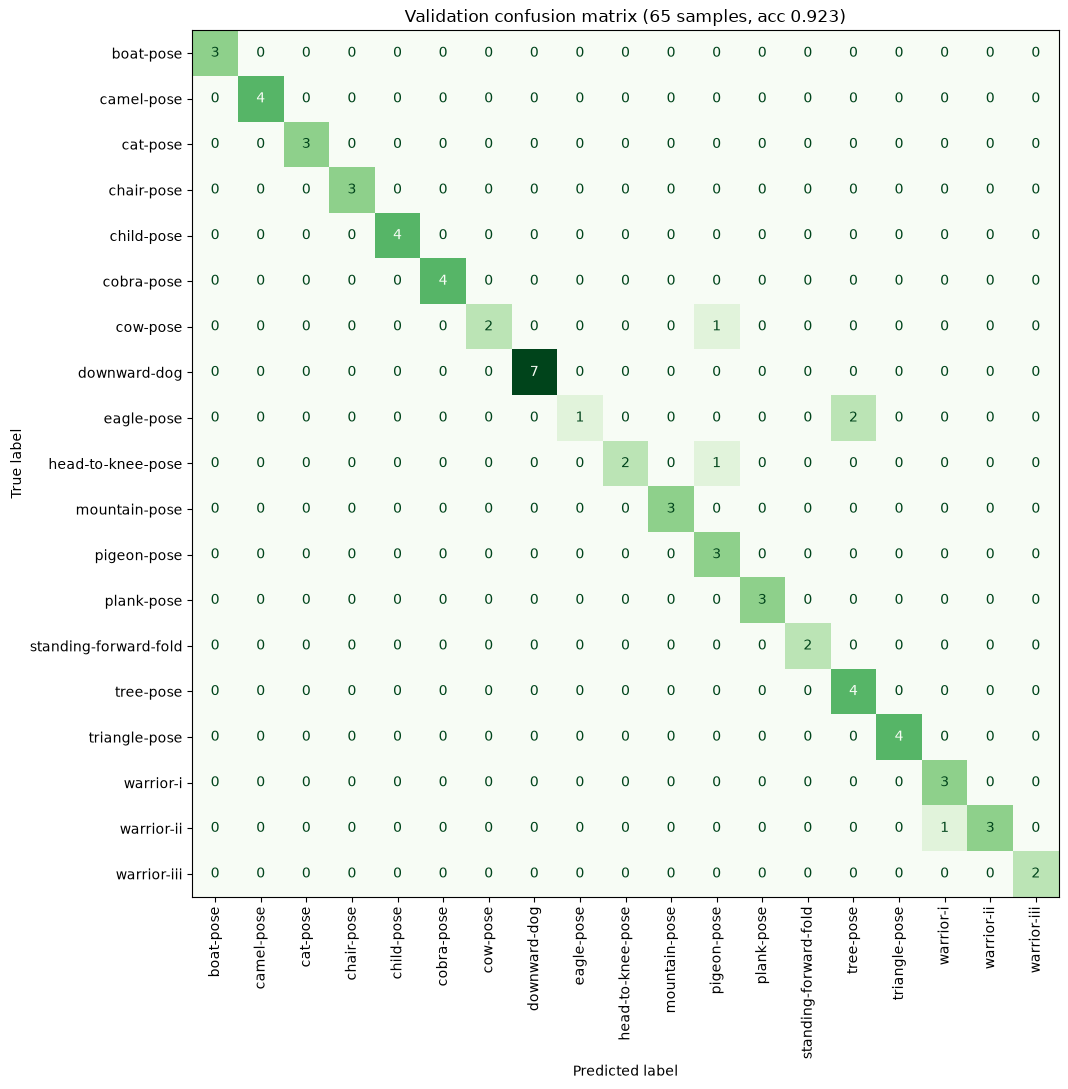

In [4]:
cm = confusion_matrix(y_val, y_pred, labels=range(len(labels)))

fig, ax = plt.subplots(figsize=(11, 11))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(
    ax=ax, cmap="Greens", colorbar=False, xticks_rotation=90
)
ax.set_title(f"Validation confusion matrix ({len(y_val)} samples, acc {acc:.3f})")
plt.tight_layout()
plt.show()

## Per-class precision, recall, F1

Support is small per class (val is 20% of a few hundred photos), so treat a
single miss as one sample, not a trend. Low-support classes swing hard on one
error.

In [5]:
report = classification_report(
    y_val, y_pred, labels=range(len(labels)), target_names=labels, digits=3, zero_division=0
)
print(report)

                       precision    recall  f1-score   support

            boat-pose      1.000     1.000     1.000         3
           camel-pose      1.000     1.000     1.000         4
             cat-pose      1.000     1.000     1.000         3
           chair-pose      1.000     1.000     1.000         3
           child-pose      1.000     1.000     1.000         4
           cobra-pose      1.000     1.000     1.000         4
             cow-pose      1.000     0.667     0.800         3
         downward-dog      1.000     1.000     1.000         7
           eagle-pose      1.000     0.333     0.500         3
    head-to-knee-pose      1.000     0.667     0.800         3
        mountain-pose      1.000     1.000     1.000         3
          pigeon-pose      0.600     1.000     0.750         3
           plank-pose      1.000     1.000     1.000         3
standing-forward-fold      1.000     1.000     1.000         2
            tree-pose      0.667     1.000     0.800  

## Most confident mistakes

Misclassifications ranked by the model's confidence in the wrong answer. A wrong
call made with high probability points at two poses the features genuinely blur
together, worth more photos or a look at the landmark quality.

In [6]:
wrong = np.where(y_pred != y_val)[0]
rows = sorted(wrong, key=lambda i: probs[i, y_pred[i]], reverse=True)
if not len(rows):
    print("no misclassifications on the validation set")
for i in rows:
    true_p = probs[i, y_val[i]]
    pred_p = probs[i, y_pred[i]]
    print(
        f"true {labels[y_val[i]]:<22} predicted {labels[y_pred[i]]:<22} "
        f"(p_pred {pred_p:.2f}, p_true {true_p:.2f})"
    )

true head-to-knee-pose      predicted pigeon-pose            (p_pred 0.94, p_true 0.00)
true eagle-pose             predicted tree-pose              (p_pred 0.65, p_true 0.06)
true eagle-pose             predicted tree-pose              (p_pred 0.56, p_true 0.08)
true cow-pose               predicted pigeon-pose            (p_pred 0.48, p_true 0.40)
true warrior-ii             predicted warrior-i              (p_pred 0.38, p_true 0.15)


## Dataset class balance

How many usable photos each pose has. Thin classes are the ones to grow next.

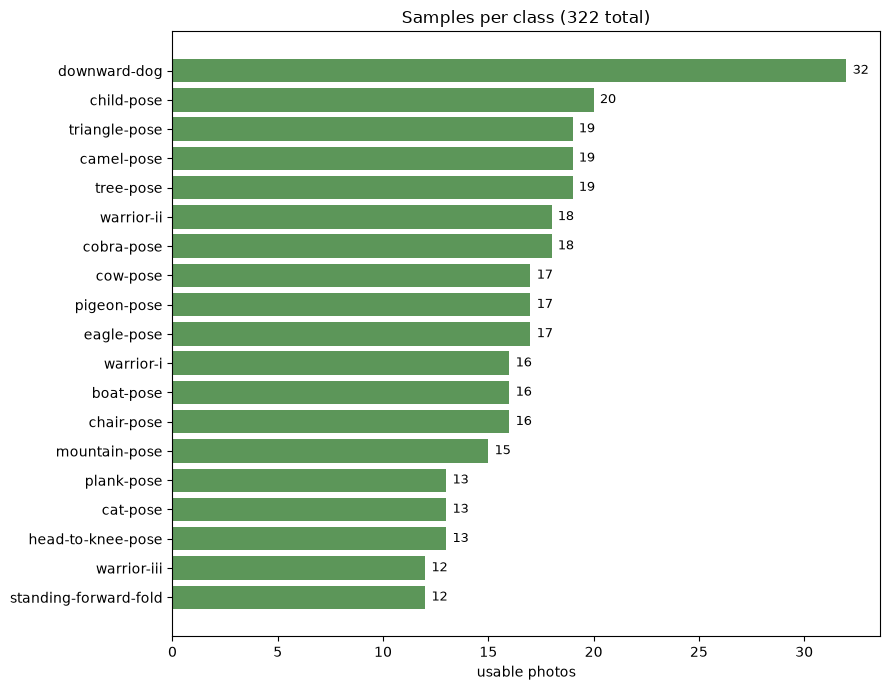

In [7]:
counts = np.bincount(y, minlength=len(labels))
order = np.argsort(counts)

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh([labels[i] for i in order], counts[order], color="#5c9659")
ax.set_xlabel("usable photos")
ax.set_title(f"Samples per class ({len(X)} total)")
for i, v in enumerate(counts[order]):
    ax.text(v + 0.3, i, str(v), va="center", fontsize=9)
plt.tight_layout()
plt.show()